### REDUCCION DE IMAGENES

In [1]:
import numpy as np
import os
import matplotlib.pyplot as plt
from astropy.io import fits
from astropy import units as u
from astropy.visualization import ZScaleInterval
from astropy.coordinates import SkyCoord
import astroalign as aa



*IMPORTANTE* los flats son de 0.5 s y los darks de 120s, po tanto restarlos directamente esta mal

In [2]:
#abrimos las imagenes de NGC7793 en el filtro B
b1=fits.open('NGC_7793_B_120.000secs_00000727.fit') 
b2=fits.open('NGC_7793_B_120.000secs_00000728.fit') #fit 728 ccorrido
b3=fits.open('NGC_7793_B_120.000secs_00000729.fit') 
b4=fits.open('NGC_7793_B_120.000secs_00000730.fit') #el fit 730 es malo
b5=fits.open('NGC_7793_B_120.000secs_00000731.fit')


In [3]:
#abrimos las imagenes de NGC7793 en el filtro V
v1=fits.open('NGC_7793_V_120.000secs_00000723.fit') #cutie
v2=fits.open('NGC_7793_V_120.000secs_00000724.fit') #this bitch is ugly
v3=fits.open('NGC_7793_V_120.000secs_00000725.fit') # LA UNICA NO CORRIDA
v4=fits.open('NGC_7793_V_120.000secs_00000726.fit')#FEA ATAOOOOOO


In [19]:
#extraemos las imagenes filtro b
datab1=b1[0].data.astype(np.float32)
datab2=b2[0].data.astype(np.float32)
datab3=b3[0].data.astype(np.float32)
datab4=b4[0].data.astype(np.float32)
datab5=b5[0].data.astype(np.float32)

#extraemos las imagenes filtro v
datav1=v1[0].data.astype(np.float32)
datav2=v2[0].data.astype(np.float32)
datav3=v3[0].data.astype(np.float32)
datav4=v4[0].data.astype(np.float32)


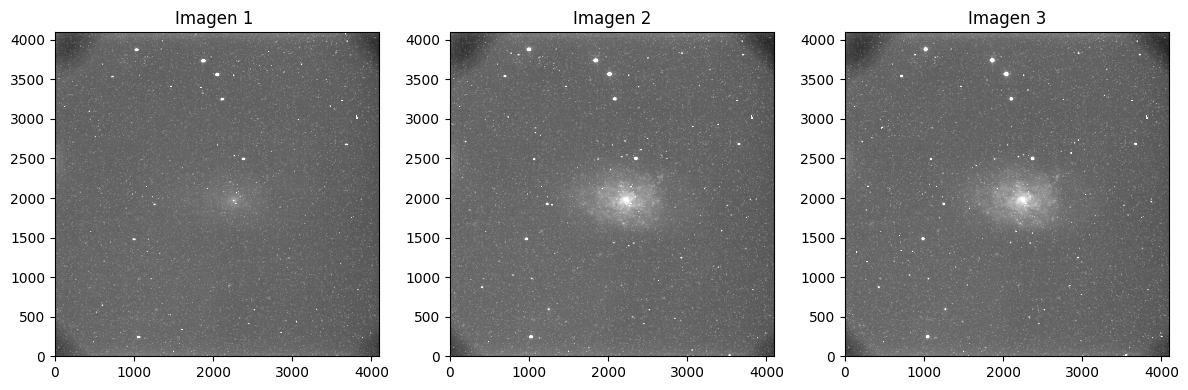

In [20]:
#graficamos algunas imagenes pa sapear
zscale=ZScaleInterval(contrast=0.25)
min_value,max_value=zscale.get_limits(datav1)
min_value,max_value=zscale.get_limits(datav3)
min_value,max_value=zscale.get_limits(datav2)
min_value,max_value=zscale.get_limits(datav4)
min_value,max_value=zscale.get_limits(datab1)
min_value,max_value=zscale.get_limits(datab3)
min_value,max_value=zscale.get_limits(datab2)
min_value,max_value=zscale.get_limits(datab4)


fig,ax=plt.subplots(1,3, figsize=(12,4))
ax[0].imshow(datab4,vmin=min_value,vmax=max_value,cmap='gray',origin='lower')
ax[0].set_title('Imagen 1 ')
ax[1].imshow(datav1,vmin=min_value,vmax=max_value,cmap='gray',origin='lower')
ax[1].set_title('Imagen 2')
ax[2].imshow(datav3,vmin=min_value,vmax=max_value,cmap='gray',origin='lower')
ax[2].set_title('Imagen 3')



plt.tight_layout()
plt.show()

### DARKS

In [6]:
# importamos los darks (trabajare con los de 120s para probar)
dark1=fits.open('Dark_120.000secs_00000774.fit')
dark2=fits.open('Dark_120.000secs_00000775.fit')
dark3=fits.open('Dark_120.000secs_00000776.fit')
dark4=fits.open('Dark_120.000secs_00000777.fit')
dark5=fits.open('Dark_120.000secs_00000778.fit')

#extraemos los datos de los darks
datad1=dark1[0].data.astype(np.float32)
datad2=dark2[0].data.astype(np.float32)
datad3=dark3[0].data.astype(np.float32)
datad4=dark4[0].data.astype(np.float32)
datad5=dark5[0].data.astype(np.float32)


In [7]:
#extraemos los datos de los darks
datad1=dark1[0].data.astype(np.float32)
datad2=dark2[0].data.astype(np.float32)
datad3=dark3[0].data.astype(np.float32)
datad4=dark4[0].data.astype(np.float32)
datad5=dark5[0].data.astype(np.float32)

### Maste Dark 

In [8]:
#estas celdas es pq si trabajo con float64 me quedo sin memoria XD
def mediana_franjas(lista, paso=256):
    """Mediana pixel a pixel ignorando NaN, procesando 256 filas a la vez."""
    ny,nx=lista[0].shape
    out=np.empty((ny,nx),dtype=np.float32)
    for y in range(0,ny,paso):
        bloque=np.stack([im[y:y+paso] for im in lista])
        out[y:y+paso]=np.nanmedian(bloque,axis=0)
    return out

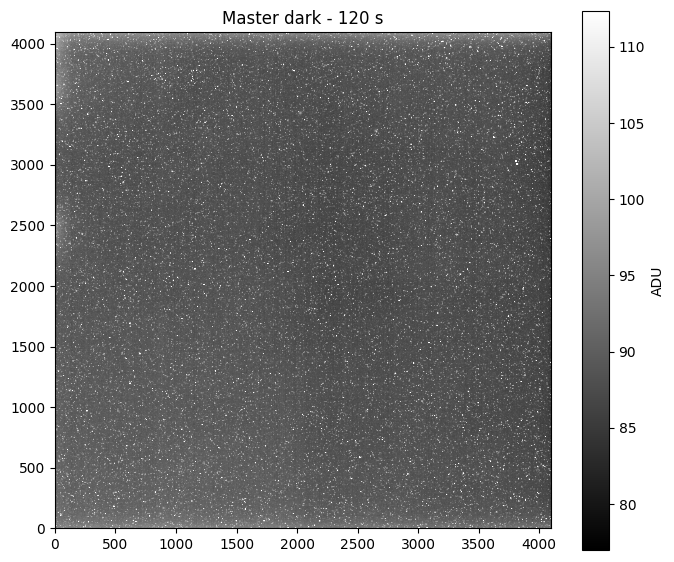

In [9]:
# creamos el master dark usando la mediana de los darks individuales
master_dark = np.nanmedian([datad1, datad2, datad3, datad4, datad5], axis=0)

zscale=ZScaleInterval(contrast=0.25)
min_value,max_value=zscale.get_limits(master_dark[np.isfinite(master_dark)])

plt.figure(figsize=(8,7))
plt.imshow(master_dark,vmin=min_value,vmax=max_value,cmap='gray',origin='lower')
plt.colorbar(label='ADU')
plt.title('Master dark - 120 s')
plt.show()

q wea tanta contaminacion 

### FLATS

flat B min/max:  0.0 2.2835290428237918
flat V min/max:  0.0 2.2835290428237918


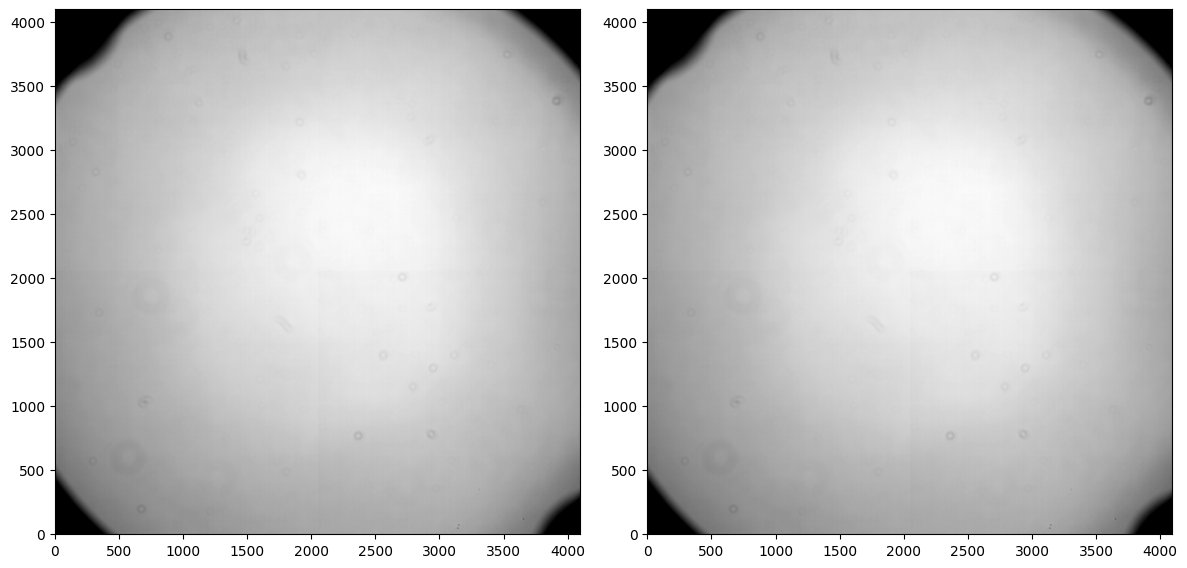

In [10]:
# extraemos los flats del filtro b
flatsB = [fits.open(f'FLAT_B_B11-{n:03}.fit')for n in range(1, 11)] #mas facil q llamar 1 x 1
#extraemos los flats del filtro v
flatsV = [fits.open(f'FLAT_V_B11-{n:03}.fit')for n in range(1, 11)]

dataflatB = np.array([f[0].data.astype(np.float64) for f in flatsB])
dataflatV = np.array([f[0].data.astype(np.float64) for f in flatsB])


#Master flat filtro V normalizado (utilizando la mediana)
master_flatv = np.nanmedian(dataflatV, axis=0)
master_flatv_norm = master_flatv / np.nanmedian(master_flatv)



#Master flat filtro b normalizado (utilizando la mediana)
master_flatb = np.nanmedian(dataflatB, axis=0)
master_flatb_norm = master_flatb / np.nanmedian(master_flatb)

print('flat B min/max: ', np.nanmin(master_flatb_norm), np.nanmax(master_flatb_norm))
print('flat V min/max: ', np.nanmin(master_flatv_norm), np.nanmax(master_flatv_norm))

fig, ax = plt.subplots(1, 2, figsize=(12, 6))
for a,f,t in [(ax[0], master_flatb_norm, 'Master Flat B'), (ax[1], master_flatv_norm, 'Master Flat V')]:
    lo, hi = ZScaleInterval(contrast=0.25).get_limits(f)
    im =a.imshow(f, vmin=lo, vmax=hi, cmap='gray', origin='lower')
plt.tight_layout()
plt.show()

In [11]:
bpm = fits.open('BPM.fit')
databpm=bpm[0].data

Valores BPM: (array([0, 1], dtype='>i2'), array([  632422, 16144794]))
Fraccion de pixeles buenos: 0.9623047113418579


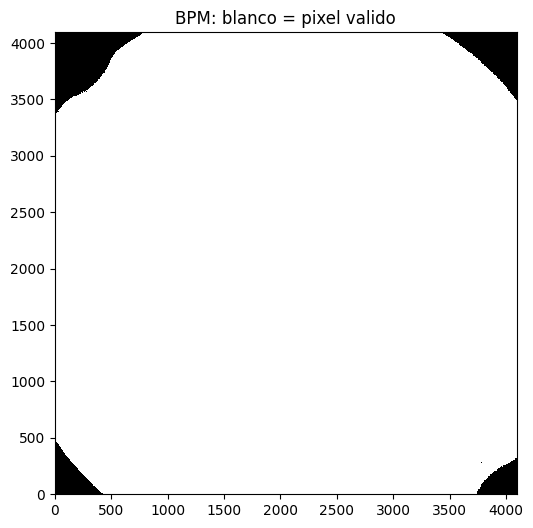

In [12]:
BPM_GOOD_VALUE=1 #1 plixel bueno, 2 pixel malo
FLAT_MIN=0.05   #evita dividir por flats casi nulos

bpm_good=(databpm==BPM_GOOD_VALUE)
print('Valores BPM:', np.unique(databpm,return_counts=True))
print('Fraccion de pixeles buenos:', bpm_good.mean())

plt.figure(figsize=(6,6))
plt.imshow(bpm_good,cmap='gray',origin='lower',interpolation='nearest')
plt.title('BPM: blanco = pixel valido')
plt.show()

#REDUCCIÓN 

In [13]:
def reducir(data, flat_norm):
    valido=(bpm_good & np.isfinite(data) & np.isfinite(master_dark)
            & np.isfinite(flat_norm) & (flat_norm>FLAT_MIN))
    red=np.full(data.shape,np.nan,dtype=np.float32)
    red[valido]=(data[valido]-master_dark[valido])/flat_norm[valido]
    return red

sel_b=[datab1,datab3,datab4]
sel_v=[datav1,datav3]

redb=[reducir(d,master_flatb_norm) for d in sel_b]
redv=[reducir(d,master_flatv_norm) for d in sel_v]

#liberamos las imagenes crudas que ya no se usan
del sel_b,sel_v,datab1,datab2,datab3,datab4,datav1,datav2,datav3,datav4

### IMAGENES FINALES

de cada img ciencia

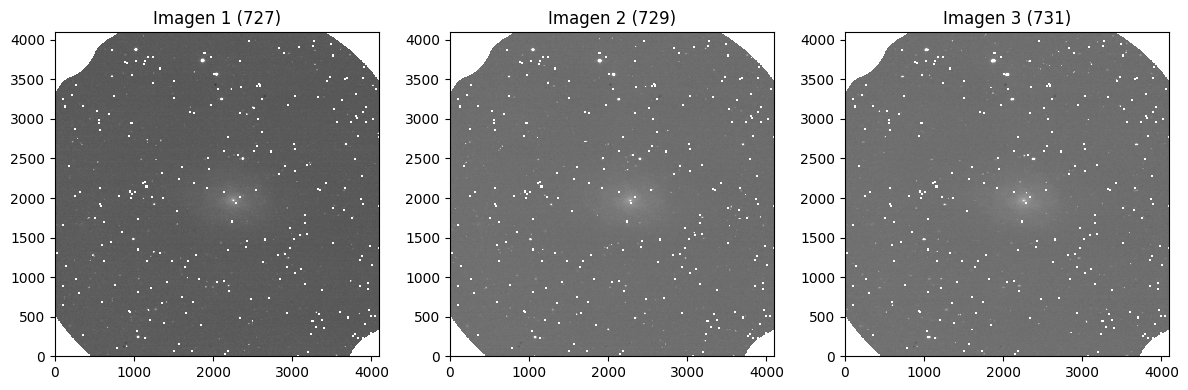

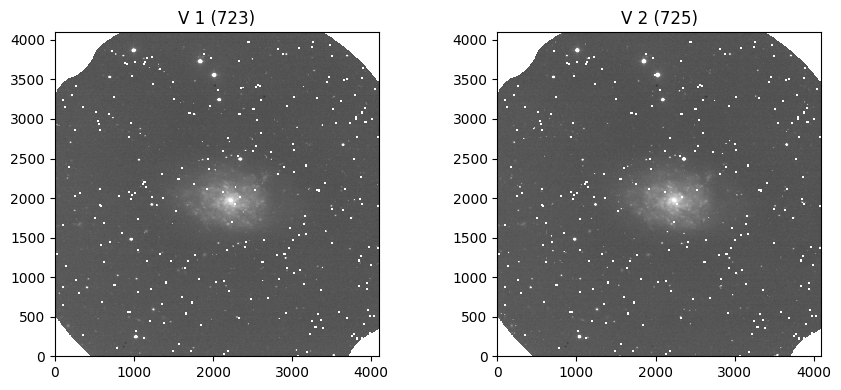

In [14]:
zscale=ZScaleInterval(contrast=0.25)

fig,ax=plt.subplots(1,3, figsize=(12,4))
titulos=['Imagen 1 (727)','Imagen 2 (729)','Imagen 3 (731)']
for a,img,t in zip(ax,redb,titulos):
    min_value,max_value=zscale.get_limits(img[np.isfinite(img)])  #limites propios de cada imagen
    a.imshow(img,vmin=min_value,vmax=max_value,cmap='gray',origin='lower')
    a.set_title(t)
plt.tight_layout()
plt.show()

fig,ax=plt.subplots(1,2, figsize=(9,4))
titulos=['V 1 (723)','V 2 (725)']
for a,img,t in zip(ax,redv,titulos):
    min_value,max_value=zscale.get_limits(img[np.isfinite(img)])
    a.imshow(img,vmin=min_value,vmax=max_value,cmap='gray',origin='lower')
    a.set_title(t)
plt.tight_layout()
plt.show()

alineamos las imagenes

In [23]:
def a_masked(img):
    #astroalign no tolera NaN: se rellenan con la mediana y se marcan en una mascara
    malo=~np.isfinite(img)
    return np.ma.array(np.where(malo,np.nanmedian(img),img),mask=malo)

def alinear(lista, ref_idx, nombres):
    ref=a_masked(lista[ref_idx])
    alineadas=[]
    for i,img in enumerate(lista):
        if i==ref_idx:
            alineadas.append(lista[i].astype(np.float32))
            print(f'{nombres[i]}: referencia')
            continue
        try:
            T,(src,dst)=aa.find_transform(a_masked(img),ref)
        except Exception as e:
            print(f'{nombres[i]}: NO se pudo alinear ({e}); se descarta')
            continue
        al,foot=aa.apply_transform(T,a_masked(img),ref,fill_value=np.nan,propagate_mask=True)
        alineadas.append(al.astype(np.float32))
        print(f'{nombres[i]}: shift (x,y)={T.translation.round(1)} px, '
              f'rot={np.degrees(T.rotation):.3f} deg, estrellas={len(src)}')
    return alineadas

#el orden de estas listas debe coincidir con el orden de redb y redv
nombres_b=['727','729','731']
nombres_v=['723','725']

alb=alinear(redb,ref_idx=nombres_b.index('729'),nombres=nombres_b)   #referencia: B 729
alv=alinear(redv,ref_idx=nombres_v.index('725'),nombres=nombres_v)   #referencia: V 725

727: NO se pudo alinear (List of matching triangles exhausted before an acceptable transformation was found); se descarta
729: referencia
731: NO se pudo alinear (List of matching triangles exhausted before an acceptable transformation was found); se descarta
723: shift (x,y)=[20.7  0.6] px, rot=-0.002 deg, estrellas=21
725: referencia


C:\Users\laneg\AppData\Local\Temp\ipykernel_23404\3476448166.py:8: RuntimeWarning: All-NaN slice encountered
  out[y:y+paso]=np.nanmedian(bloque,axis=0)


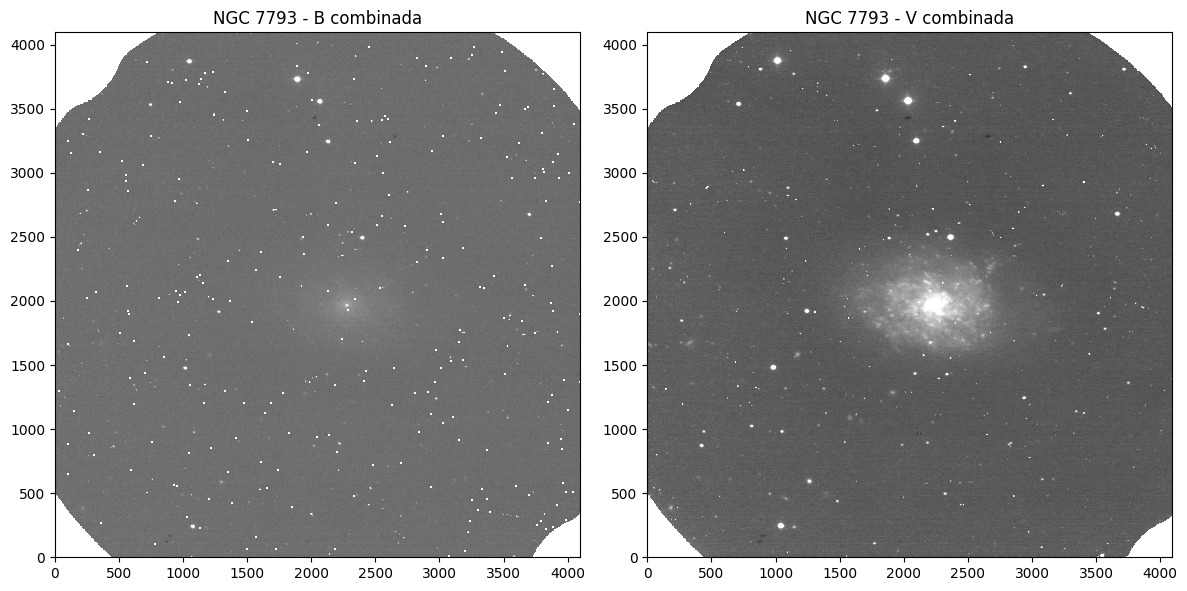

In [24]:
#graficamos ambas imagenes
final_b=mediana_franjas(alb)
final_v=mediana_franjas(alv)

fig,ax=plt.subplots(1,2,figsize=(12,6))
for a,img,t in [(ax[0],final_b,'NGC 7793 - B combinada'),(ax[1],final_v,'NGC 7793 - V combinada')]:
    lo,hi=zscale.get_limits(img[np.isfinite(img)])
    a.imshow(img,vmin=lo,vmax=hi,cmap='gray',origin='lower')
    a.set_title(t)
plt.tight_layout()
plt.show()

### FITS Y ASTROMETRIA

In [25]:
#Creación fits y astrometría

phdu = fits.PrimaryHDU(header = b1[0].header , data = final_b)
phdu.data = np.float32(phdu.data)

phdu.header['PIXSCALE'] = 0.36
phdu.header['CTYPE1'] = 'RA---TAN'
phdu.header['CTYPE2'] = 'DEC--TAN'
phdu.header['CRPIX1'] = int(phdu.header['NAXIS1']/2)
phdu.header['CRPIX2'] = int(phdu.header['NAXIS2']/2)

coord = SkyCoord(f"{phdu.header['OBJCTRA']} {phdu.header['OBJCTDEC']}", unit=(u.hourangle, u.deg))#Transformacion de unidades a grados decimales

phdu.header['CRVAL1'] = coord.ra.value
phdu.header['CRVAL2'] = coord.dec.value
phdu.header['CD1_1'] = -0.0001
phdu.header['CD1_2'] = 0
phdu.header['CD2_1'] = 0
phdu.header['CD2_2'] = 0.0001
phdu.header['OBSERVER'] = 'Bustos, Medina, Oyarzo'

phdu.writeto('Img_B.fits', overwrite = True)

In [26]:
phdu = fits.PrimaryHDU(header = v1[0].header , data = final_v)
phdu.data = np.float32(phdu.data)

phdu.header['PIXSCALE'] = 0.36
phdu.header['CTYPE1'] = 'RA---TAN'
phdu.header['CTYPE2'] = 'DEC--TAN'
phdu.header['CRPIX1'] = int(phdu.header['NAXIS1']/2)
phdu.header['CRPIX2'] = int(phdu.header['NAXIS2']/2)

coord=SkyCoord(f"{phdu.header['OBJCTRA']} {phdu.header['OBJCTDEC']}", unit=(u.hourangle, u.deg)) #Transformacion de unidades a grados decimales

phdu.header['CRVAL1'] = coord.ra.value
phdu.header['CRVAL2'] = coord.dec.value
phdu.header['CD1_1'] = -0.0001
phdu.header['CD1_2'] = 0
phdu.header['CD2_1'] = 0
phdu.header['CD2_2'] = 0.0001
phdu.header['OBSERVER'] = 'Bustos, Medina, Oyarzo'

phdu.writeto('Img_V.fits', overwrite = True)

### DETECCION DE OBJETOS

In [27]:
#deteccion de objetos
from photutils.segmentation import (SourceCatalog, deblend_sources, detect_sources, detect_threshold)
from astropy.io import fits
from matplotlib import pyplot as plt
import numpy as np

### 1- Para el filtro v

In [28]:
#abrio mi fit filtro v (imagen reduccioda)
imagenV = fits.open('Img_V.fits')[0]

#extraemos data y header
dataV = imagenV.data
headerV = imagenV.header
headerV

SIMPLE  =                    T / conforms to FITS standard                      
BITPIX  =                  -32 / array data type                                
NAXIS   =                    2 / number of array dimensions                     
NAXIS1  =                 4096                                                  
NAXIS2  =                 4096                                                  
COMMENT   FITS (Flexible Image Transport System) format is defined in 'Astronomy
COMMENT   and Astrophysics', volume 376, page 359; bibcode: 2001A&A...376..359H 
OBSERVER= 'Bustos, Medina, Oyarzo' / SBIGFITSEXT The name of the observer       
ORIGIN  = 'MAS500  '           / Description of location                        
TELESCOP= 'MAS500  '           / SBIGFITSEXT The model Telescope                
FOCALLEN=                6500. / SBIGFITSEXT Telescope focal length in mm       
APTDIA  =                 500. / SBIGFITSEXT Aperture diameter in mm            
SBUUID  = '{4962eaff-43f2-4b

In [29]:
#Obtenemos el "umbral" que utilizaremos para detectar las fuentes EN EL FILTRO V
thresholdV = detect_threshold(dataV, nsigma=1)
#Utilizamos el umbral y la imagen para detectar fuentes
sourV = detect_sources(dataV, thresholdV, npixels=10)
#Mostramos el número de fuentes detectadas
sourV

<photutils.segmentation.core.SegmentationImage>
shape: (4096, 4096)
nlabels: 20091
labels: [    1     2     3     4     5 ... 20087 20088 20089 20090 20091]

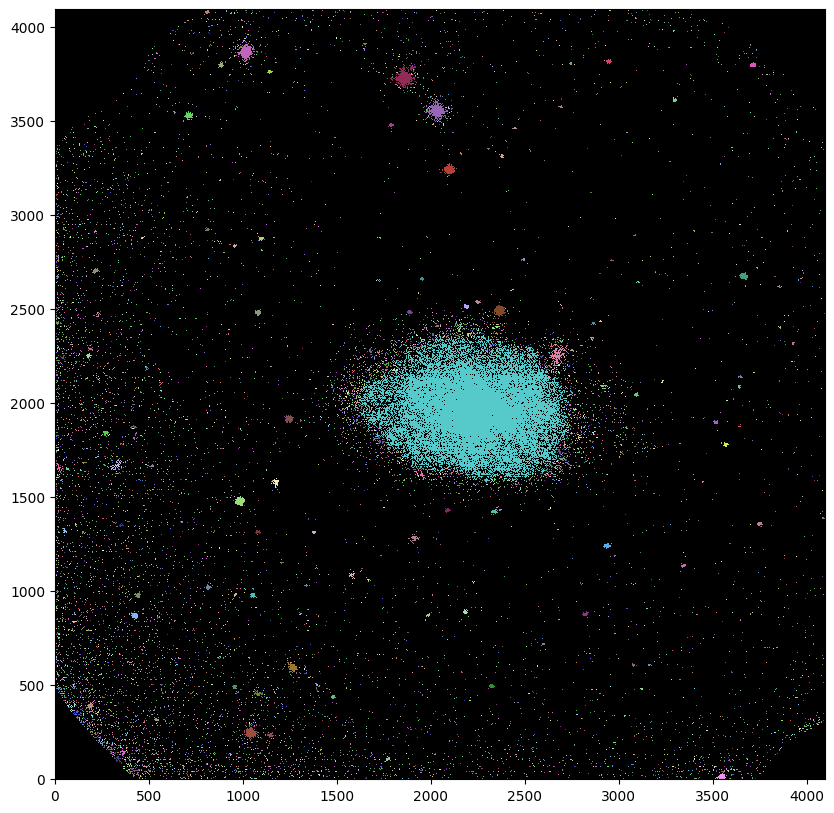

In [30]:
#Generamos un mapa de color para cada fuente del filtro V
cmap_sourV = sourV.make_cmap(seed=123)
#Mostramos las fuentes obtenidas
fig, ax = plt.subplots(1, 1, figsize=(10,10))
ax.imshow(sourV, origin='lower', cmap=cmap_sourV, interpolation='nearest')
plt.show()

In [31]:
# separamos las fuentes 
sour_deblend = deblend_sources(dataV, sourV, npixels=10, nlevels=32, contrast=1)
#esto muestra el numero de fuentes detectadas
sour_deblend

<photutils.segmentation.core.SegmentationImage>
shape: (4096, 4096)
nlabels: 20091
labels: [    1     2     3     4     5 ... 20087 20088 20089 20090 20091]

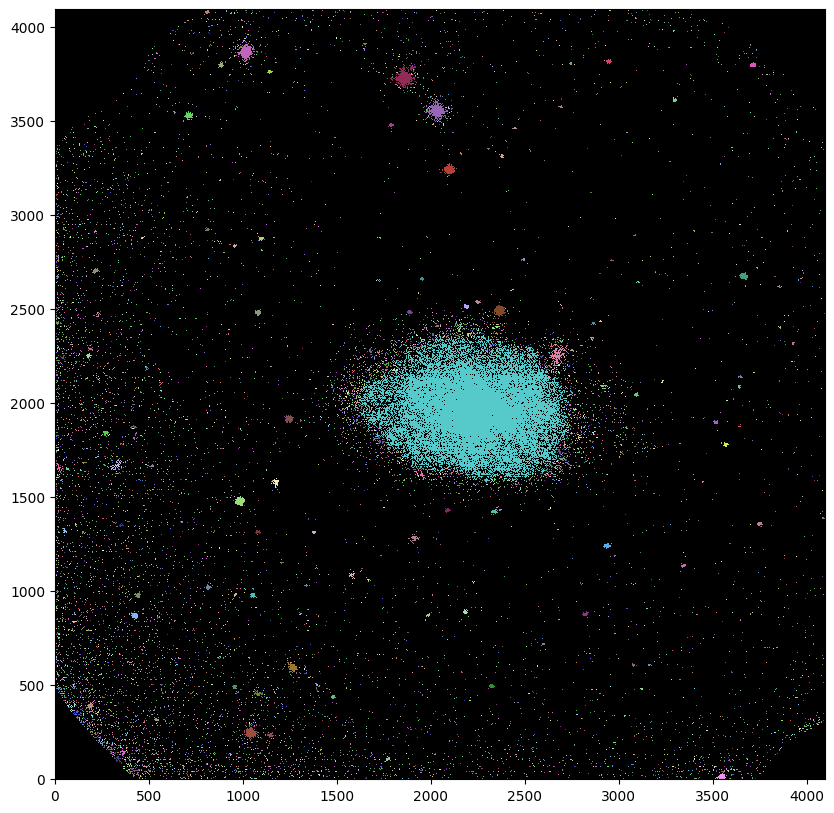

In [32]:
cmap_deblend = sour_deblend.make_cmap(seed=123)
#muesta las fuentes detectadas
fig, ax = plt.subplots(1, 1, figsize=(10,10))
ax.imshow(sour_deblend, origin='lower', cmap= cmap_deblend, interpolation='nearest')
plt.show()

In [33]:
#OBTENEMOS EL CATALOGO DE FITS REDUCIDO PARA EL FILTRO V
cat = SourceCatalog(dataV, sour_deblend)
#pasamos el catalogo a una tabla (solo con los datos que nos interesan)
tb1 = cat.to_table()
tablav = tb1['label', 'xcentroid', 'ycentroid', 'area', 'segment_flux']
#label: numero id de la fuente'
#xcentroid, ycentroid: coordenadas'
#area: tamaño en pixeles'
#segment_flux: flojo total (no es el real pq no cuenta el tiempo de exp)'

tablav

label,xcentroid,ycentroid,area,segment_flux
,,,pix2,
int32,float64,float64,float64,float64
1,432.0069678768006,7.230214689592644,99.0,2670.779296875
2,450.6903947295942,4.980002603872006,25.0,628.9139347076416
3,458.677893929163,1.0820902872795783,14.0,411.5802536010742
4,462.86800403142377,4.715775062183849,31.0,816.5603103637695
5,478.7898929284147,1.7418647449306428,25.0,731.289119720459
6,489.40406460876045,4.833560922170959,34.0,836.7924823760986
7,496.61262734478674,1.2012443427622084,14.0,381.58138847351074
8,594.4201349662682,2.456336411767099,11.0,308.1652317047119


In [34]:
#calculamos el flujo real 
tablav['segment_flux'] = tablav['segment_flux']/headerV['EXPTIME']
tablav

label,xcentroid,ycentroid,area,segment_flux
,,,pix2,
int32,float64,float64,float64,float64
1,432.0069678768006,7.230214689592644,99.0,22.256494140625
2,450.6903947295942,4.980002603872006,25.0,5.240949455897013
3,458.677893929163,1.0820902872795783,14.0,3.4298354466756185
4,462.86800403142377,4.715775062183849,31.0,6.804669253031412
5,478.7898929284147,1.7418647449306428,25.0,6.094075997670491
6,489.40406460876045,4.833560922170959,34.0,6.9732706864674885
7,496.61262734478674,1.2012443427622084,14.0,3.1798449039459227
8,594.4201349662682,2.456336411767099,11.0,2.568043597539266


In [35]:
#CALCULAMOS MAG APARENTES CON EL ZEROPONIT (NO LO TENGO LOL)
#puse un valor falso x mientras
zeropoint = 39.34044722557779
tablav['magnitude'] = zeropoint - 2.5*np.log(tablav['segment_flux'])
tablav

label,xcentroid,ycentroid,area,segment_flux,magnitude
,,,pix2,,
int32,float64,float64,float64,float64,float64
1,432.0069678768006,7.230214689592644,99.0,22.256494140625,31.58386263179075
2,450.6903947295942,4.980002603872006,25.0,5.240949455897013,35.19919053609579
3,458.677893929163,1.0820902872795783,14.0,3.4298354466756185,36.25916651233558
4,462.86800403142377,4.715775062183849,31.0,6.804669253031412,34.5464246470777
5,478.7898929284147,1.7418647449306428,25.0,6.094075997670491,34.82215434711098
6,489.40406460876045,4.833560922170959,34.0,6.9732706864674885,34.485236308797575
7,496.61262734478674,1.2012443427622084,14.0,3.1798449039459227,36.448366167431224
8,594.4201349662682,2.456336411767099,11.0,2.568043597539266,36.98258631828149


In [36]:
#Mostramos las magnitudes
np.sort(tablav['magnitude'])

10.322836813380043
14.704326363352884
14.812947424731405
15.683553647800604
18.04088691866808
18.306080365716106
18.359601248716228
19.982615492666618
21.71568068360031
22.114488737911877
22.450228889226757


### 2- Para el filtro B

In [37]:
#ahora para filtro b, abro mi fit filtro b (imagen reduccioda)
imagenB = fits.open('Img_B.fits')[0]

#extraemos data y header
dataB = imagenB.data
headerB = imagenB.header
headerB

SIMPLE  =                    T / conforms to FITS standard                      
BITPIX  =                  -32 / array data type                                
NAXIS   =                    2 / number of array dimensions                     
NAXIS1  =                 4096                                                  
NAXIS2  =                 4096                                                  
COMMENT   FITS (Flexible Image Transport System) format is defined in 'Astronomy
COMMENT   and Astrophysics', volume 376, page 359; bibcode: 2001A&A...376..359H 
OBSERVER= 'Bustos, Medina, Oyarzo' / SBIGFITSEXT The name of the observer       
ORIGIN  = 'MAS500  '           / Description of location                        
TELESCOP= 'MAS500  '           / SBIGFITSEXT The model Telescope                
FOCALLEN=                6500. / SBIGFITSEXT Telescope focal length in mm       
APTDIA  =                 500. / SBIGFITSEXT Aperture diameter in mm            
SBUUID  = '{e4f15d9a-ffbc-41

In [38]:
#Obtenemos el "umbral" que utilizaremos para detectar las fuentes EN EL FILTRO b
thresholdB = detect_threshold(dataB, nsigma=1)
#Utilizamos el umbral y la imagen para detectar fuentes
sourB = detect_sources(dataB, thresholdB, npixels=10)
#Mostramos el número de fuentes detectadas
sourB

<photutils.segmentation.core.SegmentationImage>
shape: (4096, 4096)
nlabels: 20852
labels: [    1     2     3     4     5 ... 20848 20849 20850 20851 20852]

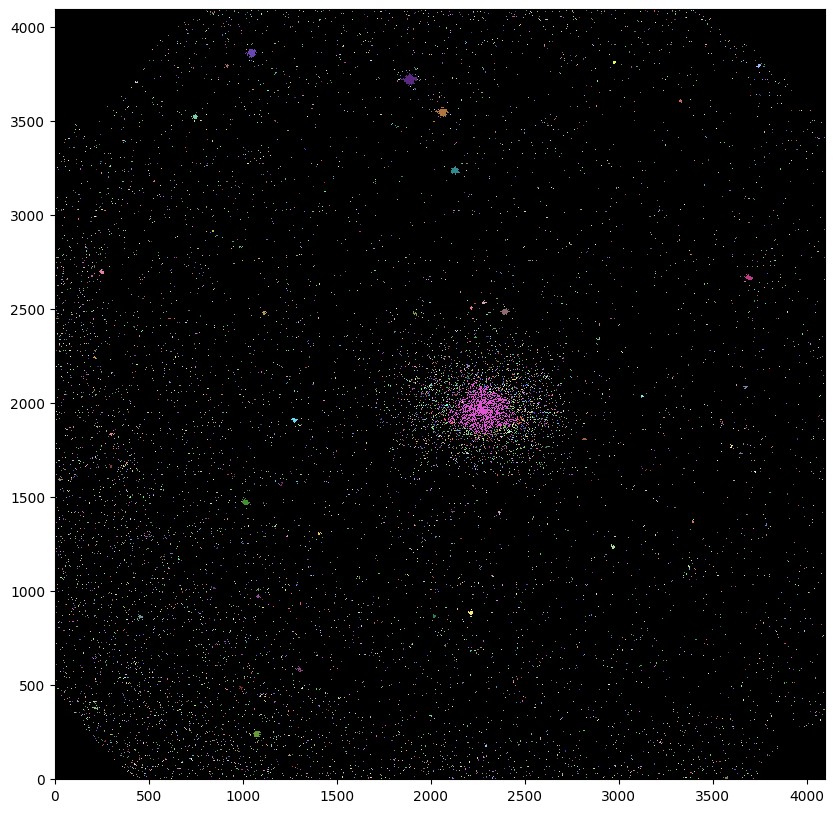

In [39]:
#Generamos un mapa de color para cada fuente del filtro B
cmap_sourB = sourB.make_cmap(seed=123)
#Mostramos las fuentes obtenidas
fig, ax = plt.subplots(1, 1, figsize=(10,10))
ax.imshow(sourB, origin='lower', cmap=cmap_sourB, interpolation='nearest')
plt.show()

In [40]:
# separamos las fuentes 
sour_deblendB = deblend_sources(dataB, sourB, npixels=10, nlevels=32, contrast=1)
#esto muestra el numero de fuentes detectadas
sour_deblendB

<photutils.segmentation.core.SegmentationImage>
shape: (4096, 4096)
nlabels: 20852
labels: [    1     2     3     4     5 ... 20848 20849 20850 20851 20852]

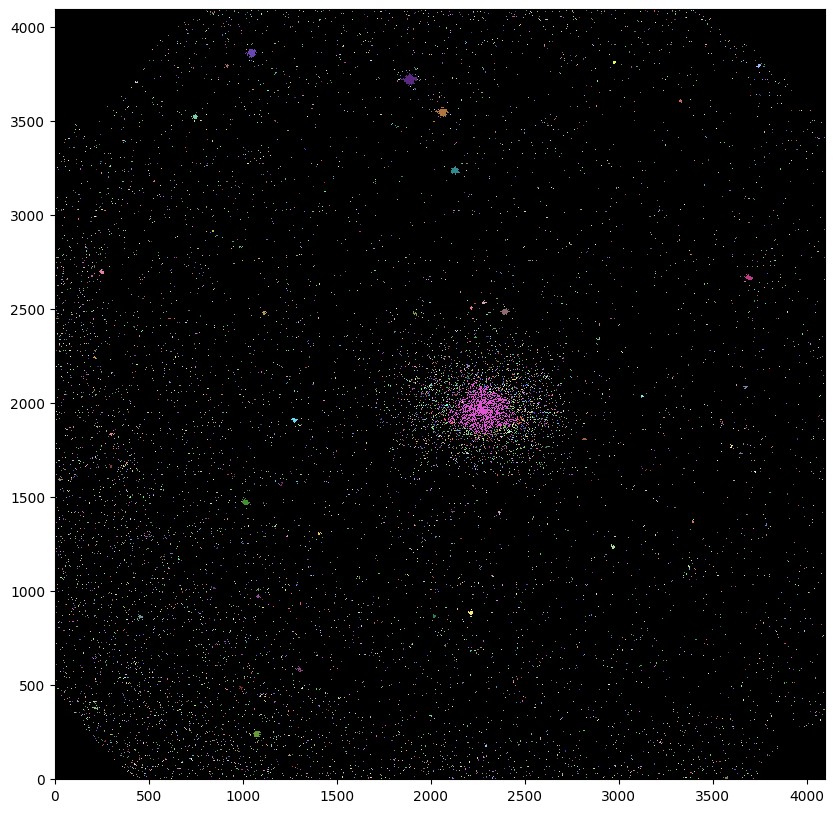

In [41]:
cmap_deblendB = sour_deblendB.make_cmap(seed=123)
#muesta las fuentes detectadas
fig, ax = plt.subplots(1, 1, figsize=(10,10))
ax.imshow(sour_deblendB, origin='lower', cmap= cmap_deblendB, interpolation='nearest')
plt.show()

In [42]:
#OBTENEMOS EL CATALOGO DE FITS REDUCIDO PARA EL FILTRO B
catB = SourceCatalog(dataB, sour_deblendB)
#pasamos el catalogo a una tabla (solo con los datos que nos interesan)
tb1B = catB.to_table()
tablaB = tb1B['label', 'xcentroid', 'ycentroid', 'area', 'segment_flux']
#label: numero id de la fuente'
#xcentroid, ycentroid: coordenadas'
#area: tamaño en pixeles'
#segment_flux: flujo total (no es el real pq no cuenta el tiempo de exp)'

tablaB

label,xcentroid,ycentroid,area,segment_flux
,,,pix2,
int32,float64,float64,float64,float64
1,426.87691066200495,2.462236589713119,13.0,383.71292877197266
2,551.8768769198394,4.213339193141001,24.0,669.3993549346924
3,560.5438377982787,2.443917001923744,15.0,487.0354347229004
4,618.0274814133741,2.954105622731374,13.0,373.52439880371094
5,642.8811018811939,0.4938395584522183,12.0,325.050989151001
6,743.8781527069825,3.3090454537219878,11.0,289.53027725219727
7,1064.4659055641653,0.5852398380384412,21.0,5172.44935798645
8,1405.9227423802233,3.2074786870857963,15.0,424.07579231262207


In [43]:
#calculamos el flujo real 
tablaB['segment_flux'] = tablaB['segment_flux']/headerB['EXPTIME']
tablaB

label,xcentroid,ycentroid,area,segment_flux
,,,pix2,
int32,float64,float64,float64,float64
1,426.87691066200495,2.462236589713119,13.0,3.197607739766439
2,551.8768769198394,4.213339193141001,24.0,5.578327957789103
3,560.5438377982787,2.443917001923744,15.0,4.058628622690836
4,618.0274814133741,2.954105622731374,13.0,3.112703323364258
5,642.8811018811939,0.4938395584522183,12.0,2.708758242925008
6,743.8781527069825,3.3090454537219878,11.0,2.412752310434977
7,1064.4659055641653,0.5852398380384412,21.0,43.10374464988708
8,1405.9227423802233,3.2074786870857963,15.0,3.5339649359385175


In [44]:
#CALCULAMOS MAG APARENTES CON EL ZEROPONIT (NO LO TENGO LOL)
#puse un valor falso x mientras
zeropoint = 39.022104169660096
tablaB['magnitude'] = zeropoint - 2.5*np.log(tablaB['segment_flux'])
tablaB

label,xcentroid,ycentroid,area,segment_flux,magnitude
,,,pix2,,
int32,float64,float64,float64,float64,float64
1,426.87691066200495,2.462236589713119,13.0,3.197607739766439,36.116096797399024
2,551.8768769198394,4.213339193141001,24.0,5.578327957789103,34.72488146379083
3,560.5438377982787,2.443917001923744,15.0,4.058628622690836,35.519991322431196
4,618.0274814133741,2.954105622731374,13.0,3.112703323364258,36.18337520857779
5,642.8811018811939,0.4938395584522183,12.0,2.708758242925008,36.53087837731715
6,743.8781527069825,3.3090454537219878,11.0,2.412752310434977,36.820183836163416
7,1064.4659055641653,0.5852398380384412,21.0,43.10374464988708,29.613079479251063
8,1405.9227423802233,3.2074786870857963,15.0,3.5339649359385175,35.86605303983671


In [45]:
#Mostramos las magnitudes
np.sort(tablaB['magnitude'])

16.633255822894053
16.763339908737066
18.90371534418953
19.530825892251578
21.46997276733734
21.71428300941197
21.7892664064387
23.29178788700133
24.088160784456825
25.018085628760133
25.482099791546908
